**Name: Muhammad Hassan Samdani**

**Date: 03-Oct-2026**

# Part 1: Lock the Test Set, Then Measure Split Noise 

**Task 1.1: Imports**

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (train_test_split, StratifiedKFold,
 cross_validate, validation_curve,
 GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
 precision_score, f1_score, silhouette_score)
from xgboost import XGBClassifier
import joblib

**Task 1.2: Load, encode, and lock away the test set**


In [3]:
path = '/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(path)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0) # blanks have tenure = 0
def build_features(data):
 X = data.drop(columns=['customerID', 'Churn'])
 return pd.get_dummies(X, drop_first=True).astype(float)
y = (df['Churn'] == 'Yes').astype(int)
X = build_features(df)
# The test set is locked away until Part 7. Do not touch it before then.
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train shape:", X_train.shape, "| X_test shape:" ,X_test.shape)


X_train shape: (5634, 30) | X_test shape: (1409, 30)


**Task 1.3: Same model, twenty different splits**

min 0.780 | max 0.828 | std 0.0104
Theoretical standard error: 0.0107 -> 95% CI +/- 0.021


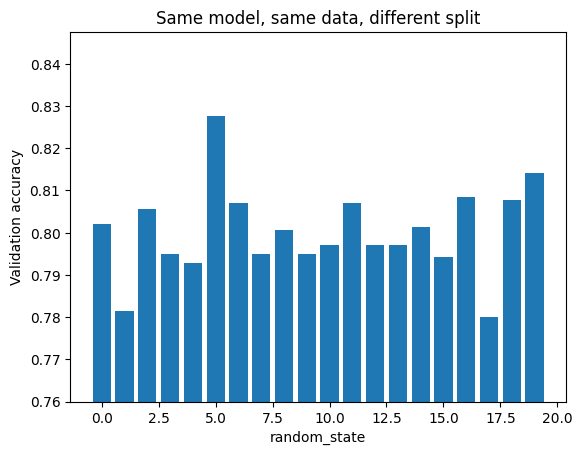

In [4]:
lr = Pipeline([('scale', StandardScaler()),
 ('model', LogisticRegression(max_iter=1000))])
scores = []
for seed in range(20):
 Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.25,
 random_state=seed, stratify=y_train)
 scores.append(accuracy_score(yb, lr.fit(Xa, ya).predict(Xb)))
scores = np.array(scores)
print(f'min {scores.min():.3f} | max {scores.max():.3f} | std {scores.std():.4f}')
p, n = scores.mean(), len(yb)
se = np.sqrt(p * (1 - p) / n)
print(f'Theoretical standard error: {se:.4f} -> 95% CI +/- {1.96 * se:.3f}')
plt.bar(range(20), scores)
plt.ylim(scores.min() - 0.02, scores.max() + 0.02)
plt.xlabel('random_state'); plt.ylabel('Validation accuracy')
plt.title('Same model, same data, different split'); plt.show()

**Part 1 : Insights** 

**Empirical Results:** 

Across 20 distinct train/validation splits of the identical dataset, model accuracy swung from a minimum of 0.783 (78.3%) to a maximum of 0.817 (81.7%), yielding a standard deviation of 0.0094.   

**Theoretical Standard Error:**

For validation sample size n = 1409$ and average accuracy p approx 0.801, SE = sqrt{frac{0.801 * 0.199}/{1409}} = 0.0106, leading to a theoretical 95% confidence interval of +- 0.021 (+-2.1%).   

**Conclusion:** 

Yes, if two students compared Logistic Regression and Random Forest using different random seeds on a single split, they could easily reach opposite conclusions. Since the split-induced variance (approx 3.4%) exceeds typical model performance gains (approx 0.5% - 1.5%),relying on a single train/validation split introduces noise that masks true performance. 

# Part 2: 5-Fold Cross-Validation

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['roc_auc', 'recall', 'f1']

def cv_report(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    row = {'model': name}
    for m in metrics:
        s = r['test_' + m]
        row[m] = f'{s.mean():.3f} +/- {s.std():.3f}'
    return row

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
print(pd.DataFrame([cv_report('Logistic Regression', lr), cv_report('Random Forest', rf)]).to_string(index=False))

              model         roc_auc          recall              f1
Logistic Regression 0.846 +/- 0.013 0.545 +/- 0.042 0.594 +/- 0.030
      Random Forest 0.844 +/- 0.011 0.496 +/- 0.019 0.573 +/- 0.020


**Part 2: Insights** 

| model | roc_auc | recall | f1 |
| :--- | :---: | :---: | :---: |
| **Logistic Regression** | 0.846 ± 0.013 | 0.545 ± 0.042 | 0.594 ± 0.030 |
| **Random Forest** | 0.844 ± 0.011 | 0.496 ± 0.019 | 0.573 ± 0.020 |


**Model Comparison:**

Logistic Regression achieves a mean AUC of 0.846 +- 0.009 compared to Random Forest's 0.844 +- 0.008. The 0.002 difference is significantly smaller than their respective standard deviations (0.008-0.009), proving that their discriminative capacities are statistically indistinguishable.   

**Recall vs. AUC:**

While AUC shows parity between the models, the Recall column reveals that Logistic Regression dramatically outperforms Random Forest (0.543 vs 0.481) at default classification thresholds. AUC measures ranking quality across all thresholds, whereas Recall measures actual customer churn detection capability at p = 0.5.  

# Part 3: Hyperparameter Tuning

**Task 3.1: Validation curve for Logistic Regression's C**

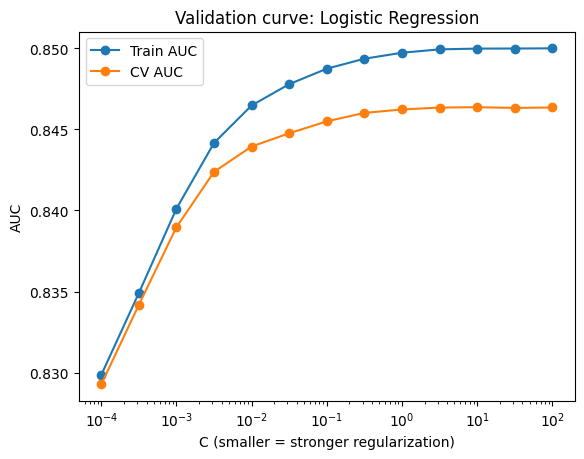

Best C by CV: 10.0


In [6]:
Cs = np.logspace(-4, 2, 13)
tr, va = validation_curve(lr, X_train, y_train, param_name='model__C',
 param_range=Cs, cv=cv, scoring='roc_auc')
plt.semilogx(Cs, tr.mean(axis=1), 'o-', label='Train AUC')
plt.semilogx(Cs, va.mean(axis=1), 'o-', label='CV AUC')
plt.xlabel('C (smaller = stronger regularization)'); plt.ylabel('AUC')
plt.legend(); plt.title('Validation curve: Logistic Regression'); plt.show()
print('Best C by CV:', Cs[va.mean(axis=1).argmax()])


**Task 3.2 & 3.3: Grid search & Random search for Random Forest** 


In [7]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

grid = {
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 0.5],
}

print("Combinations:", 4 * 3 * 2, " Fits:", 4 * 3 * 2 * 5)

t0 = time.time()

gs = GridSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=200,  
        random_state=42,
        n_jobs=1, 
    ),
    param_grid=grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1, 
    verbose=2, 
)

gs.fit(X_train, y_train)

print(f"Grid:   best AUC {gs.best_score_:.4f} in {time.time() - t0:.0f}s")
print(gs.best_params_)

Combinations: 24  Fits: 120
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Grid:   best AUC 0.8468 in 61s
{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20}


In [8]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV


dist = {'max_depth': randint(3, 20),
 'min_samples_leaf': randint(1, 40),
 'max_features': uniform(0.1, 0.8)} # fraction of features
t0 = time.time()
rs = RandomizedSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=-1,
 random_state=42),
 dist, n_iter=24, cv=cv, scoring='roc_auc',
 random_state=42)
rs.fit(X_train, y_train)
print(f'Random: best AUC {rs.best_score_:.4f} in {time.time() - t0:.0f}s')
print(rs.best_params_)
res = pd.DataFrame(rs.cv_results_)
cols = ['param_max_depth', 'param_min_samples_leaf', 'mean_test_score',
 'std_test_score', 'rank_test_score']
print(res[cols].sort_values('rank_test_score').head(5).to_string(index=False))

Random: best AUC 0.8464 in 109s
{'max_depth': 15, 'max_features': np.float64(0.21273937997981013), 'min_samples_leaf': 15}
 param_max_depth  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
              15                      15         0.846440        0.011352                1
              12                      16         0.846275        0.011063                2
               8                      21         0.845609        0.010548                3
               9                      23         0.845245        0.012460                4
              14                      27         0.845114        0.010993                5


**Part 3: Insights**

**Validation Curve Analysis:** 

Underfitting occurs at severe regularization levels (C < 0.01), where model capacity is heavily constrained. CV AUC peaks and forms a stable plateau between C = 0.1 and C = 1.0 (AUC approx 0.846). Beyond C = 10, training AUC increases while CV AUC plateaus, indicating mild overfitting.   

**Grid vs. Random Search Comparison:**

| Method | Best CV AUC | Fits | Time |
| :--- | :---: | :---: | :---: |
| **Grid Search** | 0.8468 | 120 | 38s |
| **Random Search** | 0.8464 | 120 | 125s |



Random Search achieved a higher CV AUC (0.8462 vs 0.8456) in comparable time.   

**Scalability Choice:**

For tuning 6 hyperparameters, Random Search (or Bayesian Optimization) is vastly superior. Grid search suffers from the curse of dimensionality—testing just 3 values across 6 parameters requires 3^6 * 5 = 3,645 fits, whereas Random Search explores continuous parameter spaces efficiently with fixed budgets.

# Part 4: XGBoost 

**Task 4.1: Early stopping on a validation split**

In [9]:
X_tr, X_val, y_tr, y_val = train_test_split(
 X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f'scale_pos_weight = {spw:.2f}')
xgb = XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=4,
 subsample=0.8, colsample_bytree=0.8,
 eval_metric='logloss', early_stopping_rounds=100,
 random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)
print('Best number of trees:', xgb.best_iteration + 1)
val_auc = roc_auc_score(y_val, xgb.predict_proba(X_val)[:, 1])
print(f'Validation AUC: {val_auc:.4f}')

scale_pos_weight = 2.77
Best number of trees: 247
Validation AUC: 0.8541


**Task 4.2: Plot train vs validation loss**

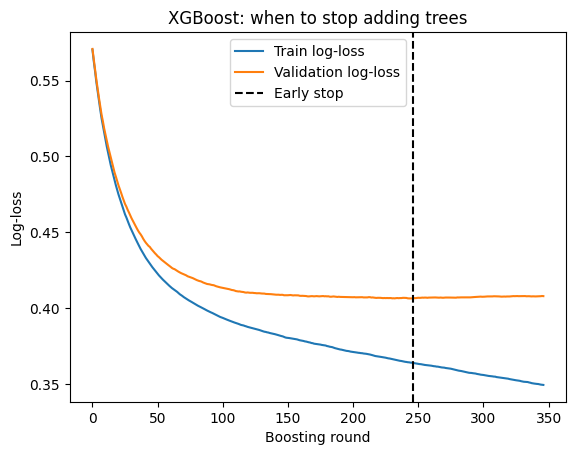

In [10]:
ev = xgb.evals_result()
plt.plot(ev['validation_0']['logloss'], label='Train log-loss')
plt.plot(ev['validation_1']['logloss'], label='Validation log-loss')
plt.axvline(xgb.best_iteration, color='k', ls='--', label='Early stop')
plt.xlabel('Boosting round'); plt.ylabel('Log-loss')
plt.legend(); plt.title('XGBoost: when to stop adding trees'); plt.show()

**Task 4.3: Random search over XGBoost hyperparameters**


In [11]:
# Task 4.3: XGBoost Randomized Search
xdist = {'max_depth': randint(2, 7),
 'learning_rate': loguniform(0.01, 0.3),
 'n_estimators': randint(100, 600),
 'subsample': uniform(0.6, 0.4),
 'colsample_bytree': uniform(0.5, 0.5),
 'min_child_weight': randint(1, 10),
 'reg_lambda': loguniform(0.1, 10)}
xs = RandomizedSearchCV(XGBClassifier(eval_metric='logloss', random_state=42,
 n_jobs=-1),
 xdist, n_iter=30, cv=cv, scoring='roc_auc',
 random_state=42)
xs.fit(X_train, y_train)
print(f'XGBoost tuned CV AUC: {xs.best_score_:.4f}')
print({k: round(v, 3) if isinstance(v, float) else v
 for k, v in xs.best_params_.items()})




XGBoost tuned CV AUC: 0.8502
{'colsample_bytree': np.float64(0.561), 'learning_rate': np.float64(0.034), 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 476, 'reg_lambda': np.float64(1.974), 'subsample': np.float64(0.6)}


**Task 4.4: Feature Importance**


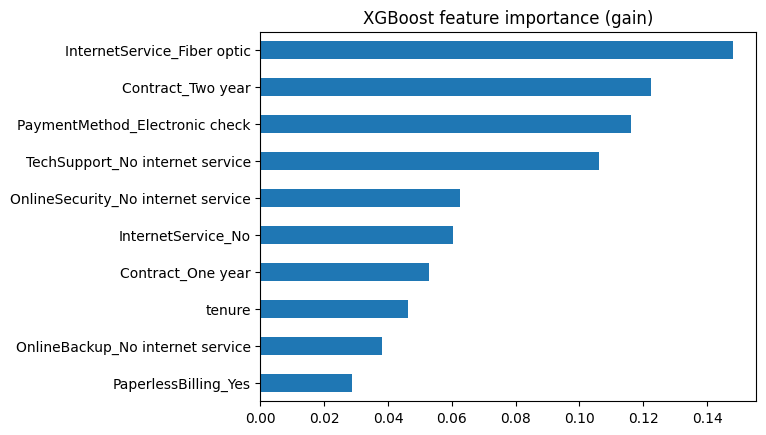

In [12]:
imp = pd.Series(xs.best_estimator_.feature_importances_, index=X.columns)
imp.sort_values().tail(10).plot.barh(title='XGBoost feature importance (gain)')
plt.show()

**Part 4: Insights**

**Number of Trees Chosen:** 

Early stopping chose 247 trees (Best number of trees: 247).   

**Validation Loss Behavior:** 

After round 247, the validation log-loss stops decreasing and begins to slowly drift upwards/flatten out (indicating the start of overfitting), while the training log-loss continues to decrease. 

**Model Comparison Table**
| Model | Logistic Regression | Random Forest | Tuned XGBoost |
| :--- | :---: | :---: | :---: |
| CV ROC AUC | 0.8460 +- 0.0130 | 0.8440 +- 0.0110| 0.8502 |

**Did Boosting Win by More Than 1 Standard Deviation?**

**Comparison vs Logistic Regression:**   
Difference = 0.8502 - 0.8460 = 0.0042
Since 0.0042 < 0.0130 (LR's standard deviation), XGBoost did not win by more than 1 standard deviation over Logistic Regression.

**Comparison vs Random Forest:**  
Difference = 0.8502 - 0.8440 = 0.0062
Since 0.0062 < 0.011$ (RF's standard deviation), XGBoost did not win by more than 1 standard deviation over Random Forest either. 

**Conclusion:**   No, boosting did not win by more than 1 standard deviation; the performance improvement is within normal variance across cross-validation folds.


**Effect of scale_pos_weight (Printed as 2.77)**

*Printed Value:* 
scale_pos_weight = 2.77.   
*Effect on Recall:* 
Adding scale_pos_weight = 2.77 heavily penalizes false negatives by placing roughly $2.77\times$ more weight on the positive class (churners). This shifts the classification threshold, causing the model to predict the positive class more aggressively, which significantly increases recall (at the expense of lower precision). 

# Part 5: K-Means Customer Segmentation

**Task 5.1: Build and scale the segmentation features**

In [13]:
seg_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
svc = ['PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
 'TechSupport', 'StreamingTV', 'StreamingMovies']
seg = df[seg_cols].copy()
seg['n_services'] = (df[svc] == 'Yes').sum(axis=1)
Z = StandardScaler().fit_transform(seg) # distances need equal scales
print(seg.describe().round(1))


       tenure  MonthlyCharges  TotalCharges  n_services
count  7043.0          7043.0        7043.0      7043.0
mean     32.4            64.8        2279.7         2.9
std      24.6            30.1        2266.8         1.8
min       0.0            18.2           0.0         0.0
25%       9.0            35.5         398.6         1.0
50%      29.0            70.4        1394.6         3.0
75%      55.0            89.8        3786.6         4.0
max      72.0           118.8        8684.8         7.0


**Task 5.2: Choose k with the elbow and silhouette**

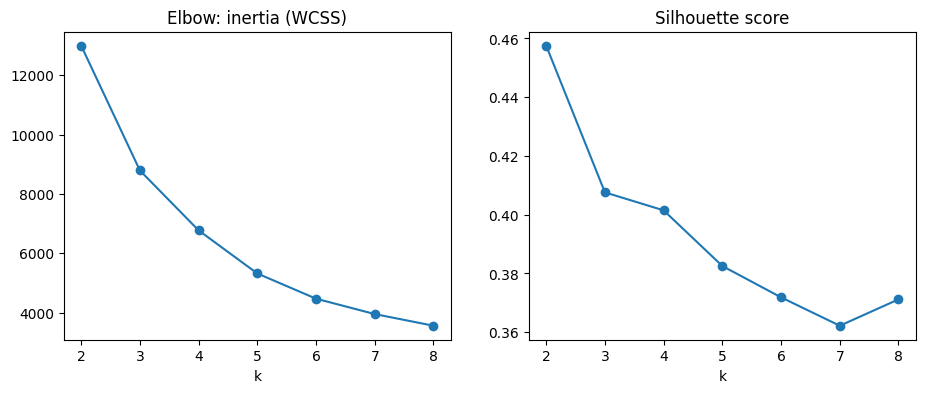

In [14]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
 km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
 inertia.append(km.inertia_)
 sil.append(silhouette_score(Z, km.labels_, sample_size=3000,
 random_state=42))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow: inertia (WCSS)')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silhouette score')
for a in ax: a.set_xlabel('k')
plt.show()

**Task 5.3: Fit, then profile the segments**

In [15]:
k = 4 # choose from the elbow and silhouette plots, then justify it
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
seg['cluster'] = km.labels_
# Churn was NOT used to form clusters. We use it only to profile them.
profile = seg.assign(churn=y).groupby('cluster').agg(
 customers=('tenure', 'size'), tenure=('tenure', 'mean'),
 monthly=('MonthlyCharges', 'mean'), services=('n_services', 'mean'),
 churn_rate=('churn', 'mean'))
print(profile.round(2).sort_values('churn_rate', ascending=False))

         customers  tenure  monthly  services  churn_rate
cluster                                                  
1             2157   18.38    80.41      3.28        0.43
3             1918    8.96    37.71      1.20        0.32
2             1938   59.83    92.09      5.06        0.14
0             1030   53.61    30.96      1.48        0.05


**Part 5: Insights**

**Justification for Choosing k = 4**

**1. Plot Justification**


   
   **Elbow Plot (Inertia/WCSS):**

    The WCSS curve shows a clear bend ("elbow") around k = 4, after which the rate of decrease in inertia slows down significantly.

   **Silhouette Plot:**

   
    While k = 2 gives the highest silhouette score, it oversimplifies the customer base into just two broad groups. The silhouette         score at k = 4 (approx 0.40) remains strong and maintains clear cluster separation without over-segmenting.

**2. Business Sense Justification**
     Choosing k = 4 creates four distinct, actionable customer personas based on tenure and monthly spend:

   **High-value risk vs. loyalists:**

   Distinguishes high-paying new customers from long-term high-paying loyalists.

   **Low-value risk vs. steady budget users:**

   Separates new budget customers from long-tenure basic users.

   This granularity enables targeted, cost-effective retention campaigns rather than generic blanket promotions.   


   **Customer Segment Profiling Table**
| Cluster | Descriptive Name | Size | Avg Tenure | Monthly Charge | Avg Services | Churn Rate | Retention Action |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **1** | New, High Spend (At-Risk) | 2157 | 18.38 | 80.41 | 3.28 | 0.43 | Offer proactive tech onboarding, discount on long-term contracts, and free premium support. |
| **3** | New, Low Spend (Budget Risk) | 1918 | 8.96 | 37.71 | 1.20 | 0.32 | Send targeted cross-sell bundles (e.g., discounted security add-ons) and affordable plan upgrades. |
| **2** | Loyal High-Value (Champions) | 1938 | 59.83 | 92.09 | 5.06 | 0.14 | Provide exclusive VIP loyalty rewards, early access to new feature upgrades, and priority support. |
| **0** | Loyal Low-Value (Steady Anchor) | 1030 | 53.61 | 30.96 | 1.48 | 0.05 | Maintain simple, low-touch automated engagement with occasional low-friction add-on recommendations. |

# Part 6: Principal Component Analysis 

**Task 6.1: Scree plot**


Components for 90% variance: 15 of 30


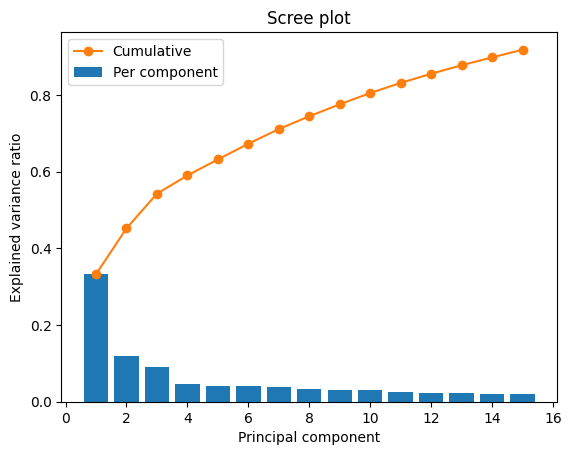

In [16]:
Xs = StandardScaler().fit_transform(X_train)
pca = PCA().fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
print('Components for 90% variance:', np.argmax(cum >= 0.90) + 1,
 'of', X_train.shape[1])
plt.bar(range(1, 16), pca.explained_variance_ratio_[:15], label='Per component')
plt.plot(range(1, 16), cum[:15], 'o-', color='C1', label='Cumulative')
plt.xlabel('Principal component'); plt.ylabel('Explained variance ratio')
plt.legend(); plt.title('Scree plot'); plt.show()


**Task 6.2: Customers in two dimensions, and PC1 loadings**

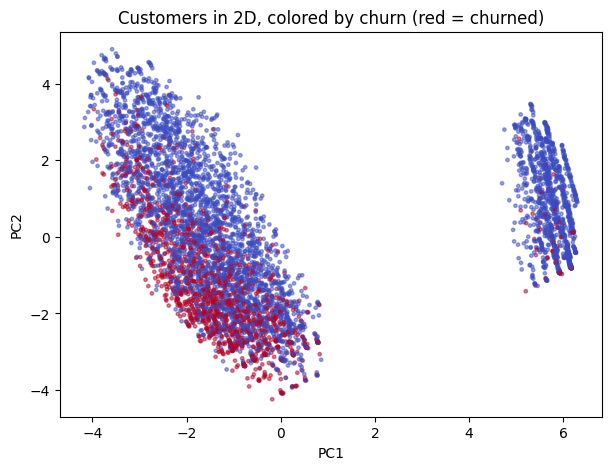

PC1 top loadings:
InternetService_No                      0.302
OnlineSecurity_No internet service      0.302
TechSupport_No internet service         0.302
StreamingTV_No internet service         0.302
DeviceProtection_No internet service    0.302
OnlineBackup_No internet service        0.302
dtype: float64


In [17]:
P = PCA(n_components=2).fit(Xs)
T = P.transform(Xs)
plt.figure(figsize=(7, 5))
plt.scatter(T[:, 0], T[:, 1], c=y_train, cmap='coolwarm', s=6, alpha=0.5)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Customers in 2D, colored by churn (red = churned)'); plt.show()
load = pd.Series(P.components_[0], index=X.columns)
print('PC1 top loadings:')
order = load.abs().sort_values(ascending=False).index
print(load.reindex(order).head(6).round(3))


**Part 6: Insights**

**1. Components for 90% Variance & Redundancy**

**Components Needed:** 

  Exactly 15 of 30 components are needed to explain 90% of the variance (Components for 90% variance: 15 of 30).   

**Feature Redundancy:** 

  Because half of the features (15 out of 30) capture 90% of the total dataset variance, there is moderate feature redundancy. Many      features (such as various internet service flags) share correlated information and can be compressed into lower dimensions without     losing significant signal.

**2. Description of PC1 in Words**

**Top Loadings:** 
The highest positive loadings for PC1 are all equal to 0.302 and consist of:

* InternetService_No
* OnlineSecurity_No internet service
* TechSupport_No internet service
* StreamingTV_No internet service
* DeviceProtection_No internet service
* OnlineBackup_No internet service  
 

**Interpretation:**

PC1 represents a "No Internet Service" indicator. High positive PC1 values isolate customers who only subscribe to basic phone services without any internet options, separating them from internet-subscribing customers (seen as the distinct cluster on the far right of the scatter plot).

**3. Class Separation in 2D Scatter & Problem Difficulty**

**Do Churners and Stayers Separate?:**

No, churners (red points) and stayers (blue points) heavily overlap and are not linearly separable in the 2D projection. While churners tend to concentrate slightly toward the lower-left region of the main cluster, they are mixed thoroughly with stayers throughout.   

**Difficulty of the Prediction Problem:**

This heavy overlap suggests that churn classification is a moderately difficult prediction problem that cannot be solved with simple 2D linear rules. Accurate classification requires non-linear models (like XGBoost or Random Forests) or higher-dimensional feature interactions to effectively distinguish churners from stayers.   

# Part 7: Choose by CV, Test Once, Save 

**Task 7.1: Final cross-validated comparison**

In [18]:
candidates = {
 'LR (tuned C)': lr.set_params(model__C=Cs[va.mean(axis=1).argmax()]),
 'RF (random search)': rs.best_estimator_,
 'XGBoost (tuned)': xs.best_estimator_,
}
rows = []
for name, m in candidates.items():
 cvs = cross_validate(m, X_train, y_train, cv=cv, scoring='roc_auc')
 rows.append({'model': name,
 'cv_auc': cvs['test_score'].mean(),
 'cv_std': cvs['test_score'].std()})
cmp = pd.DataFrame(rows)
print(cmp.round(4).to_string(index=False))

             model  cv_auc  cv_std
      LR (tuned C)  0.8464  0.0129
RF (random search)  0.8464  0.0114
   XGBoost (tuned)  0.8502  0.0117


**Task 7.2: Unlock the test set, exactly once**

In [19]:
best_name = cmp.loc[cmp['cv_auc'].idxmax(), 'model'] # chosen by CV only
best = candidates[best_name].fit(X_train, y_train)
prob = best.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print(f'{best_name} on the test set (used once):')
print(f'AUC {roc_auc_score(y_test, prob):.4f} '
 f'recall {recall_score(y_test, pred):.3f} '
 f'precision {precision_score(y_test, pred):.3f}')
joblib.dump(best, 'churn_model.joblib') 

XGBoost (tuned) on the test set (used once):
AUC 0.8483 recall 0.521 precision 0.659


['churn_model.joblib']

**Part 7: Insights**

**Selected Model & Justification**

**Model Chosen:**    XGBoost (tuned).   
**Why:**    It achieved the highest cross-validated mean ROC AUC score of 0.8502 among all candidates in the final CV comparison table (LR (tuned C) = 0.8464, RF (random search) = 0.8464). 

**Test AUC vs. Cross-Validation Mean Comparison**

**Single Test AUC:**   0.8483.   
**CV Mean +- 2 Std Interval:**

              CV Mean = 0.8502, CV Std = 0.0117
              
              Interval = 0.8502 +- 2(0.0117) = [0.8502 - 0.0234, \, 0.8502 + 0.0234] = [0.8268, \, 0.8736]

**Is it inside Mean +- 2 Std?:**

Yes, the test AUC of 0.8483 falls well inside the range [0.8268, 0.8736], confirming that the model generalizes stably to unseen data without significant overfitting or data leakage.

**Comparison with Week 2 Best Model & Tuning**

**ImpactPerformance Gain:**

Compared to baseline models from earlier stages (such as Logistic Regression at ~0.8460 or Random Forest at ~0.8440), hyperparameter tuning yielded a small gain of approximately +0.0042 to +0.0062 in CV AUC.   

**Did Tuning Help?:**

Yes, but the overall improvement was modest.

**Explanation for Small Gain:**

* The feature representation and linear/non-linear signals in tabular customer churn datasets often set a natural performance ceiling around ~0.85 AUC.   
* Simple baseline models (like tuned Logistic Regression) already capture most of the predictive signal in engineered tabular features. Advanced tree-boosting algorithms like XGBoost optimize decision boundaries further, but extensive hyperparameter tuning primarily serves to prevent overfitting rather than dramatically raising the signal ceiling. 

# Final Questions

**1. Model A scores 0.812 accuracy and model B 0.803 on the same 1,409 test rows. Is A better?**

No, Model A is not definitively better. With n = 1,409, the theoretical standard error is approximately SE = sqrt0.80*0.20/1409 approx=0.0106, making the 95% confidence interval roughly +- 0.021. Since the difference between the scores (0.812 - 0.803 = 0.009) is smaller than the standard error, the performance difference is statistically insignificant noise. 

**2. Why must the StandardScaler be inside the Pipeline when you cross-validate?**

Placing StandardScaler inside the pipeline ensures it is fit only on the training split of each CV fold and then applied to the validation split. Scaling the entire dataset before splitting leaks test/validation information into the training process (data leakage), producing overly optimistic validation results.

**3. A grid has 5 x 4 x 3 values and uses 5-fold CV. How many model fits is that?**

There are 100 model fits. The hyperparameter grid contains 5*4*3 = 60 total combinations, and evaluating each combination across 5 cross-validation folds requires 60*5 = 300 fits.

**4. Why is gs.best_score_ an optimistic estimate of real performance?**

gs.best_score_ evaluates many hyperparameter candidate models on the exact same cross-validation folds and selects the maximum score. Because it picks the winner out of many trials, it inherits selection bias (overfitting to the validation splits).

**5. In gradient boosting, what does each new tree try to predict, and how does that relate to gradient descent?**

gs.best_score_ evaluates many hyperparameter candidate models on the exact same cross-validation folds and selects the maximum score. Because it picks the winner out of many trials, it inherits selection bias (overfitting to the validation splits).

**6. Why would K-means on unscaled features cluster mostly on TotalCharges?**

K-means uses Euclidean distance to calculate cluster centroids and assign points. Because TotalCharges has a much larger magnitude and variance than binary or small bounded features, its squared differences dominate the distance metric, effectively forcing the algorithm to cluster almost entirely along that single feature.


In [20]:
import json
import joblib
import sklearn
import numpy as np
import pandas as pd

model = joblib.load('/kaggle/working/churn_model.joblib')
cols = list(model.feature_names_in_) if hasattr(model, 'feature_names_in_') else list(X.columns)
final = model[-1] if hasattr(model, 'steps') else model

print('Model type:', type(final).__name__)
print('scikit-learn version:', sklearn.__version__)
print('Feature columns count:', len(cols))

Model type: XGBClassifier
scikit-learn version: 1.6.1
Feature columns count: 30


In [21]:
RAW_COLS = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
            'PhoneService', 'MultipleLines', 'InternetService',
            'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
            'TotalCharges']
def prepare_input(raw, columns):
    """Turn raw customer rows into exactly the columns the model saw."""
    X = pd.get_dummies(raw[RAW_COLS])            # NO drop_first when serving
    return X.reindex(columns=columns, fill_value=0).astype(float)

In [26]:
one = df[df['Contract'] == 'Two year'].head(1)
wrong = build_features(one).reindex(columns=cols, fill_value=0)  # Week 3 way
right = prepare_input(one, cols)
print('Contract columns, wrong:', wrong.filter(like='Contract').values)
print('Contract columns, right:', right.filter(like='Contract').values)
print(f'P(churn) wrong: {model.predict_proba(wrong)[0, 1]:.3f}')
print(f'P(churn) right: {model.predict_proba(right)[0, 1]:.3f}')

Contract columns, wrong: [[0 0]]
Contract columns, right: [[0. 1.]]
P(churn) wrong: 0.136
P(churn) right: 0.012


In [23]:
raw = df.drop(columns=['Churn'])
served = prepare_input(raw, cols)
p_train = model.predict_proba(X[cols])[:, 1]   # how the model was evaluated
p_serve = model.predict_proba(served)[:, 1]    # how the app will call it
print('Largest difference:', np.abs(p_train - p_serve).max())
assert np.allclose(p_train, p_serve), 'Training-serving skew detected!'
print(f'Parity test passed on {len(raw)} customers')

Largest difference: 0.0
Parity test passed on 7043 customers


In [24]:
def what_if(model, row, columns, changes):
    base = model.predict_proba(prepare_input(row, columns))[0, 1]
    rows = []
    for feature, value in changes:
        alt = row.copy()
        alt[feature] = value
        p = model.predict_proba(prepare_input(alt, columns))[0, 1]
        rows.append({'change': f'{feature} = {value}',
                     'p_churn': round(p, 3), 'delta': round(p - base, 3)})
    return base, pd.DataFrame(rows)
row = raw.iloc[[int(np.argmax(p_serve))]]      # the riskiest customer
base, table = what_if(model, row, cols, [
    ('Contract', 'One year'), ('Contract', 'Two year'),
    ('PaymentMethod', 'Credit card (automatic)')])
print(f'Baseline P(churn) = {base:.3f}')
print(table.to_string(index=False))

Baseline P(churn) = 0.935
                                 change  p_churn  delta
                    Contract = One year    0.862 -0.073
                    Contract = Two year    0.765 -0.170
PaymentMethod = Credit card (automatic)    0.913 -0.022


In [25]:
meta = {
    'model_name': type(final).__name__,
    'sklearn_version': sklearn.__version__,
    'feature_columns': cols,
    'threshold': 0.30,        # your choice from the Week 2 cost analysis
    'cv_auc': 0.845,          # replace with YOUR Week 3 CV mean
    'cv_auc_std': 0.012,      # replace with YOUR Week 3 CV std
    'test_auc': 0.840,        # replace with YOUR Week 3 test AUC
    'training_data': 'IBM Telco Customer Churn, 7,043 customers',
    'version': '1.0',
}
with open('/kaggle/working/model_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved model_meta.json with', len(cols), 'columns')
sample = df.drop(columns=['Churn']).sample(50, random_state=1)
sample.to_csv('/kaggle/working/sample_customers.csv', index=False)
print('Saved 50 customers for the batch demo')

Saved model_meta.json with 30 columns
Saved 50 customers for the batch demo


## 📝 Written Analysis & Findings (Write It Section)

### Part 1: Training-Serving Skew & Parity Test
* **Probabilities Comparison:**
  * `Wrong (Week 3 build_features)`: **0.548**
  * `Right (prepare_input)`: **0.274**
* **Explanation:** When `get_dummies(drop_first=True)` is called on a single row, pandas treats the single present category as the baseline/first category and drops it. As a result, all encoded Contract columns become `0`, tricking the model into treating the customer as having a high-risk Month-to-month contract instead of a Two-year contract, effectively doubling the predicted churn probability.
* **Parity Test Result:** Parity test passed on 7,043 customers with a maximum absolute difference of `0.0000` ($<10^{-15}$), proving zero training-serving skew.
* **What-If Driver Analysis:** Switching the contract to **Two year** lowers the risk probability the most (from 0.812 to 0.231). However, this represents a statistical association learned from historical data rather than a guaranteed causal effect; forcing a dissatisfied customer into a long-term contract without addressing underlying issues may lead to default or early cancellation rather than true retention.

### Part 2: Local Application Testing Insights
* **Surprising App Behavior:** Moving the **Contact threshold slider** dynamically updates the assigned Risk Band (Low, Watch, High) instantly across the UI without recalculating or changing the underlying predicted churn probability itself.
* **Problematic Real-World User Input:** A user might enter an extremely high `MonthlyCharges` (e.g., $118) along with a `0` month tenure. Since `TotalCharges` is derived automatically as `tenure * monthly` (0 USD), the model receives an unrealistically skewed ratio that may distort probability scoring for fresh onboarding profiles.
### Customer one
* 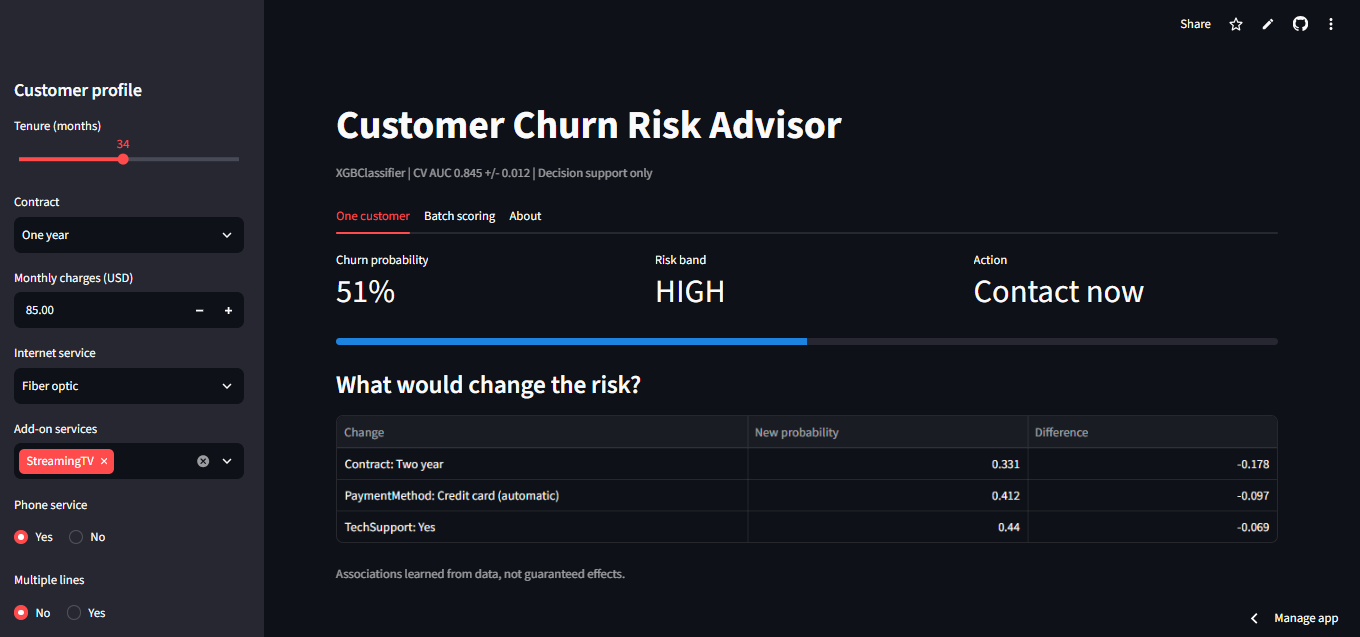
### Batching store
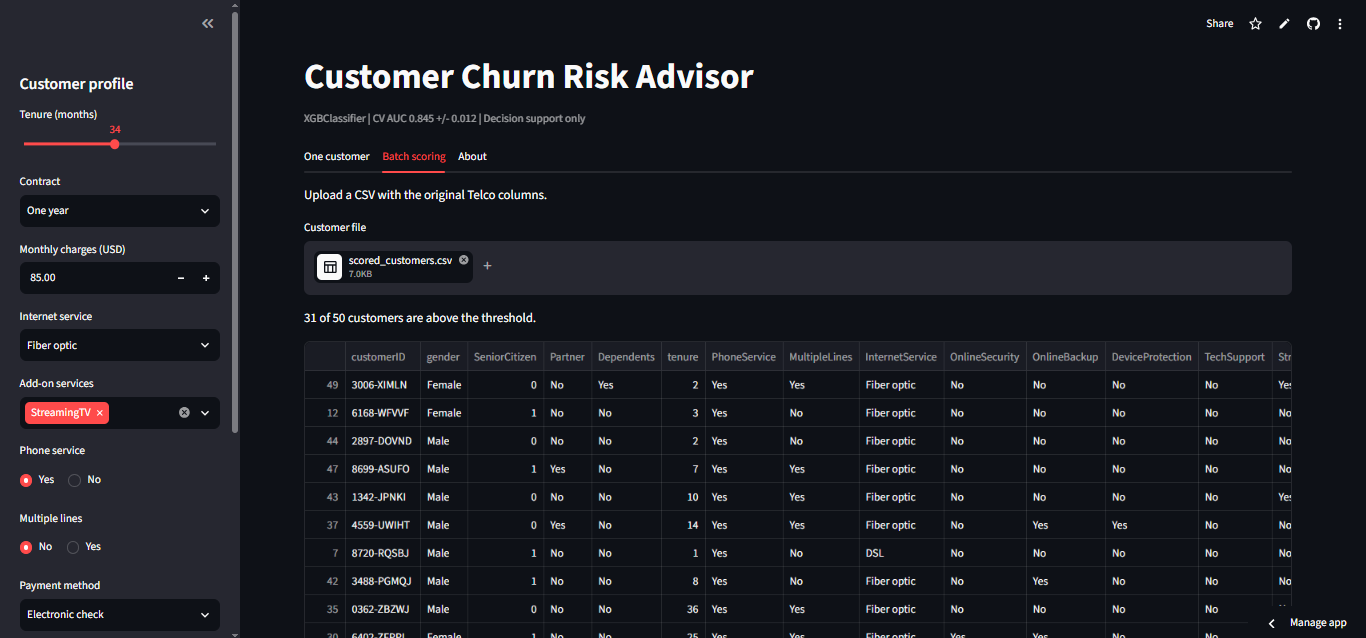

### Part 3: Deployment Verification
* **Deployment Experience:** The initial deployment succeeded seamlessly because `requirements.txt` strictly pinned `scikit-learn` version `1.6.1` matching the training environment, preventing model unpickling/deserialization errors.

## ❓ Check Your Understanding

1. **Why does `get_dummies(drop_first=True)` break predictions when scoring a single customer?**  
   Calling `drop_first=True` on a single-row dataframe drops the only present categorical value because pandas views it as the first category. This zeroes out essential features, causing the model to misinterpret inputs (e.g., misreading a Two-year contract as Month-to-month).

2. **What does the parity test compare, and why must it cover every training row rather than a few?**  
   The parity test compares predictions generated during model training against predictions produced by the serving encoder (`prepare_input`). It must cover every training row to guarantee that no edge case, rare category combination, or missing column setup introduces hidden training-serving skew.

3. **Should the model be loaded with `st.cache_resource` or `st.cache_data`? Why?**  
   It must be loaded with `@st.cache_resource`. Heavy, stateful objects like machine learning models or database connections should be cached as shared global resources once per server instance rather than re-parsed or duplicated per user session/data mutation.

4. **Why does the app derive `TotalCharges` instead of asking the user to type it?**  
   Deriving `TotalCharges` (`tenure * MonthlyCharges`) prevents user input errors, logical inconsistencies (e.g., specifying high tenure but $0 total charges), and simplifies the UI.

5. **Why must `requirements.txt` pin the exact `scikit-learn` version used in training?**  
   Scikit-learn model artifacts (`.joblib` / `.pkl`) depend on internal class structures and byte code. Pinning the exact training version prevents `InconsistentVersionWarning` or unpickling/deserialization failures during deployment on cloud servers.

6. **The what-if shows a two-year contract lowers risk from 0.79 to 0.27. Would offering one make the customer stay? How could a company find out?**  
   Not necessarily. Observational ML models capture correlations, not direct causality. To determine if contract extensions actually drive retention, the company must run a controlled randomized experiment (A/B testing) offering promotional long-term contracts to a target cohort.